# CFRP-CFRP Failure Mode

## Imports

In [1]:
import os
import json
import time
import pickle
import warnings
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import shap
import xgboost as xgb
import lightgbm as lgb
from catboost import CatBoostRegressor, CatBoostClassifier
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import MinMaxScaler, StandardScaler
from sklearn.compose import TransformedTargetRegressor
from sklearn.model_selection import GroupKFold, KFold, GridSearchCV, train_test_split, cross_val_predict
from sklearn.inspection import permutation_importance
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error, accuracy_score, f1_score, confusion_matrix, ConfusionMatrixDisplay
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet, BayesianRidge, LogisticRegression
from sklearn.svm import SVR, SVC
from sklearn.neural_network import MLPRegressor, MLPClassifier
from sklearn.tree import DecisionTreeRegressor, DecisionTreeClassifier
from sklearn.ensemble import (RandomForestRegressor, RandomForestClassifier, ExtraTreesRegressor, ExtraTreesClassifier,
                              GradientBoostingRegressor, GradientBoostingClassifier, AdaBoostRegressor, AdaBoostClassifier)
from sklearn.neighbors import KNeighborsRegressor, KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.gaussian_process import GaussianProcessRegressor, GaussianProcessClassifier
from sklearn.gaussian_process.kernels import RBF, Matern, WhiteKernel, ConstantKernel as C

warnings.filterwarnings('ignore')
sns.set_theme(style='ticks', context='notebook')

/usr/local/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Settings

In [2]:
TASK = 'CFRP_CFRP__FailureMode'
FOLDER = 'CFRP_CFRP'
SEED = 42
SCORING = 'f1_macro'
RESULTS = '../results'
os.makedirs(f'{RESULTS}/models', exist_ok=True)

## Data

In [3]:
df = pd.read_csv(f'../data/processed/{FOLDER}/{TASK}.csv')
df.head()

,Row_ID,Paper_ID,Value_Type,Target_Is_Derived,No_Plies,Adherend1_Thickness_mm,Adherend2_Thickness_mm,Adherend1_Modulus_GPa,Adherend2_Modulus_GPa,Adherend1_Strength_MPa,...,Surf_Peel_ply,Surf_Plasma_corona,Surf_UV_ozone,Surf_Laser,Surf_Chemical_electrochemical,Surf_Other_modifier,Surf_None_as_received,Surf_Ultrasonic_vibration_assisted,Surf_Unknown,Failure_Mode
0,21,2,Lower,0,16.0,2.40,2.40,111.0,111.0,1690.0,...,0,0,0,0,0,0,0,0,0,2
1,22,2,Mean,0,16.0,2.40,2.40,111.0,111.0,1690.0,...,0,0,0,0,0,0,0,0,0,2
2,23,2,Upper,0,16.0,2.40,2.40,111.0,111.0,1690.0,...,0,0,0,0,0,0,0,0,0,2
3,27,4,Single,0,NaN,2.48,2.48,67.6,67.6,885.0,...,1,0,0,0,0,0,0,0,0,0
4,28,4,Single,0,NaN,2.48,2.48,67.6,67.6,885.0,...,1,0,0,0,0,0,0,0,0,0


In [4]:
print(df.shape, df['Paper_ID'].nunique())
df.describe().T

(587, 51) 29


,count,mean,std,min,25%,50%,75%,max
Row_ID,587.0,741.252129,402.500505,21.0000,339.5000,867.000,1112.5000,1338.000000
Paper_ID,587.0,43.045997,19.848821,2.0000,24.0000,48.000,64.0000,70.000000
Target_Is_Derived,587.0,0.000000,0.000000,0.0000,0.0000,0.000,0.0000,0.000000
No_Plies,411.0,10.138686,4.823493,2.0000,7.0000,8.000,12.0000,32.000000
Adherend1_Thickness_mm,575.0,2.110330,0.631341,1.4000,1.5200,2.000,2.5400,4.000000
Adherend2_Thickness_mm,575.0,2.110330,0.631341,1.4000,1.5200,2.000,2.5400,4.000000
Adherend1_Modulus_GPa,390.0,92.144897,43.954763,55.0000,67.6000,72.000,85.6300,230.000000
Adherend2_Modulus_GPa,390.0,92.144897,43.954763,55.0000,67.6000,72.000,85.6300,230.000000
Adherend1_Strength_MPa,189.0,1176.258942,611.525404,650.0000,650.0000,650.000,1811.2000,2180.000000
Adherend2_Strength_MPa,189.0,1176.258942,611.525404,650.0000,650.0000,650.000,1811.2000,2180.000000


In [5]:
classes = {0: 'Adhesive', 1: 'Cohesive', 2: 'Mixed', 3: 'Substrate'}
df['Failure_Mode'].map(classes).value_counts()

Failure_Mode
Cohesive     263
Mixed        135
Substrate    123
Adhesive      66
Name: count, dtype: int64

## Train-Test Split

In [6]:
meta_cols = ['Row_ID', 'Paper_ID', 'Value_Type', 'Target_Is_Derived']
target = df.columns[-1]

X = df.drop(columns=meta_cols + [target])
y = df[target]
groups = df['Paper_ID'].values

idx = np.arange(len(df))
train_idx, test_idx = train_test_split(idx, test_size=0.2, random_state=SEED)

X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]
print(len(train_idx), len(test_idx), len(set(groups[train_idx])), 'studies in the training part')

469 118 29 studies in the training part


## Helper Functions

In [7]:
FAMILY = {'OLS': 'Linear', 'Ridge': 'Linear', 'Lasso': 'Linear', 'ElasticNet': 'Linear', 'LogReg-L2': 'Linear', 'LogReg-L1': 'Linear',
          'SVR': 'Kernel', 'SVC': 'Kernel', 'MLP': 'Neural net', 'DT': 'Tree', 'RF': 'Forest', 'ET': 'Forest',
          'GB': 'Boosting', 'XGB': 'Boosting', 'LGBM': 'Boosting', 'AB': 'Boosting', 'CatBoost': 'Boosting',
          'KNN': 'Nearest neighbour', 'BayesRidge': 'Bayesian', 'GPR': 'Bayesian', 'GPC': 'Bayesian', 'GNB': 'Bayesian'}


def make_pipeline(model, impute=True, scale_target=False):
    # median imputation (fitted on the training data), MinMax scaling to [0, 1], then the model
    if scale_target and not True:
        model = TransformedTargetRegressor(regressor=model, transformer=StandardScaler())
    steps = [('imputer', SimpleImputer(strategy='median'))] if impute else []
    return Pipeline(steps + [('scaler', MinMaxScaler()), ('model', model)])


def get_scores(y_true, y_pred):
    if True:
        return dict(acc=accuracy_score(y_true, y_pred), f1=f1_score(y_true, y_pred, average='macro'))
    return dict(r2=r2_score(y_true, y_pred), mae=mean_absolute_error(y_true, y_pred), mse=mean_squared_error(y_true, y_pred))

In [8]:
results = []
predictions = {}
fitted = {}
KEY = 'f1'


def evaluate(name, model, param_grid, impute=True, scale_target=False):
    start = time.time()
    prefix = 'model__regressor__' if (scale_target and not True) else 'model__'
    n_splits = min(5, len(set(groups[train_idx])))

    # Step 1: grid search on the training part, folds grouped by study
    grid = GridSearchCV(make_pipeline(model, impute, scale_target), {prefix + k: v for k, v in param_grid.items()},
                        cv=GroupKFold(n_splits), scoring=SCORING, n_jobs=2, refit=False, error_score=np.nan)
    grid.fit(X_train, y_train, groups=groups[train_idx])
    best_params = {k[len(prefix):]: v for k, v in grid.best_params_.items()}
    build = lambda: make_pipeline(clone(model).set_params(**best_params), impute, scale_target)

    # Step 2: refit on the whole training part and score both parts
    t0 = time.perf_counter()
    best = build().fit(X_train, y_train)
    fit_time = time.perf_counter() - t0
    t0 = time.perf_counter()
    pred_test = best.predict(X_test)
    pred_time = (time.perf_counter() - t0) / len(test_idx) * 1000
    pred_train = best.predict(X_train)
    train_scores = get_scores(y_train, pred_train)
    test_scores = get_scores(y_test, pred_test)

    # Step 3: random 5-fold on the training part (leakage diagnostic) and study-grouped out-of-fold predictions
    random_cv = cross_val_predict(build(), X_train, y_train, cv=KFold(5, shuffle=True, random_state=0))
    oof = cross_val_predict(build(), X_train, y_train, cv=GroupKFold(n_splits), groups=groups[train_idx])

    # Step 4: five further random 80:20 splits with the tuned settings
    seeds = []
    for s in range(5):
        a, b = train_test_split(idx, test_size=0.2, random_state=s)
        p = build().fit(X.iloc[a], y.iloc[a]).predict(X.iloc[b])
        seeds.append(get_scores(y.iloc[b], p)[KEY])

    proba = None
    if True and hasattr(best, 'predict_proba'):
        try:
            proba = best.predict_proba(X_test)
        except Exception:
            proba = None

    fitted[name] = best
    predictions[name] = dict(train_idx=train_idx, test_idx=test_idx, y_train=y_train.values, y_test=y_test.values,
                             pred_train=pred_train, pred_test=pred_test, oof=oof, random_cv=random_cv, proba=proba)
    joblib.dump(best, f'{RESULTS}/models/{TASK}__{name}.joblib')
    row = dict(File=TASK, Target=target, Family=FAMILY[name], Model=name, Rows=len(df), Papers=len(set(groups)),
               Best_params=json.dumps({k: str(v) for k, v in best_params.items()}),
               GroupCV_tuned=round(grid.best_score_, 4),
               GroupOOF_score=round(get_scores(y_train, oof)[KEY], 4),
               Random5fold_score=round(get_scores(y_train, random_cv)[KEY], 4))
    row.update({f'Train_{k}': round(v, 4) for k, v in train_scores.items()})
    row.update({f'Test_{k}': round(v, 4) for k, v in test_scores.items()})
    row.update(Test5seeds_mean=round(float(np.mean(seeds)), 4), Test5seeds_sd=round(float(np.std(seeds)), 4),
               Fit_s=round(fit_time, 3), Pred_ms_per_row=round(pred_time, 4))
    results.append(row)
    print(name, f'test {KEY} = {test_scores[KEY]:.3f}', f'group CV = {grid.best_score_:.3f}', f'{time.time() - start:.0f}s')

## Logistic Regression (L2)

In [9]:
model = LogisticRegression(max_iter=5000)
param_grid = {'C': [0.1, 1, 10, 100]}
evaluate('LogReg-L2', model, param_grid)

LogReg-L2 test f1 = 0.787 group CV = 0.261 3s


## Logistic Regression (L1)

In [10]:
model = LogisticRegression(penalty='l1', solver='saga', max_iter=5000)
param_grid = {'C': [0.1, 1, 10, 100]}
evaluate('LogReg-L1', model, param_grid)

LogReg-L1 test f1 = 0.778 group CV = 0.327 12s


## SVC

In [11]:
model = SVC(probability=True, random_state=0)
param_grid = {'C': [1, 10, 100], 'gamma': [0.01, 0.05, 0.2]}
evaluate('SVC', model, param_grid)

SVC test f1 = 0.824 group CV = 0.223 2s


## MLP

In [12]:
model = MLPClassifier(max_iter=2000, early_stopping=True, random_state=0)
param_grid = {'hidden_layer_sizes': [(64,), (128, 64)], 'alpha': [1e-4, 1e-2]}
evaluate('MLP', model, param_grid)

MLP test f1 = 0.626 group CV = 0.155 2s


## Decision Tree

In [13]:
model = DecisionTreeClassifier(random_state=0)
param_grid = {'max_depth': [6, 12, None], 'min_samples_leaf': [1, 3]}
evaluate('DT', model, param_grid)

DT test f1 = 0.844 group CV = 0.226 1s


## RF

In [14]:
model = RandomForestClassifier(random_state=0, n_jobs=1)
param_grid = {'n_estimators': [200, 400], 'max_depth': [None, 12], 'min_samples_leaf': [1, 2]}
evaluate('RF', model, param_grid)

RF test f1 = 0.851 group CV = 0.215 18s


## Extra Trees

In [15]:
model = ExtraTreesClassifier(random_state=0, n_jobs=1)
param_grid = {'n_estimators': [200, 400], 'max_depth': [None, 12], 'min_samples_leaf': [1, 2]}
evaluate('ET', model, param_grid)

ET test f1 = 0.930 group CV = 0.248 14s


## GB

In [16]:
model = GradientBoostingClassifier(random_state=0)
param_grid = {'n_estimators': [100, 200], 'max_depth': [3, 5]}
evaluate('GB', model, param_grid)

GB test f1 = 0.930 group CV = 0.153 18s


## XGB

In [17]:
model = xgb.XGBClassifier(random_state=0, n_jobs=1, subsample=0.8, colsample_bytree=0.8)
param_grid = {'n_estimators': [300, 600], 'max_depth': [4, 6], 'learning_rate': [0.05, 0.1]}
evaluate('XGB', model, param_grid, impute=False)

XGB test f1 = 0.930 group CV = 0.176 12s


## LGBM

In [18]:
model = lgb.LGBMClassifier(random_state=0, n_jobs=1, verbose=-1)
param_grid = {'n_estimators': [300, 600], 'num_leaves': [15, 31], 'learning_rate': [0.05, 0.1]}
evaluate('LGBM', model, param_grid, impute=False)

LGBM test f1 = 0.932 group CV = 0.240 10s


## Adaboost

In [19]:
model = AdaBoostClassifier(random_state=0)
param_grid = {'n_estimators': [100, 300], 'learning_rate': [0.1, 0.5, 1.0]}
evaluate('AB', model, param_grid)

AB test f1 = 0.486 group CV = 0.225 10s


## CatBoost

In [20]:
model = CatBoostClassifier(random_seed=0, verbose=0, thread_count=1, allow_writing_files=False)
param_grid = {'iterations': [300, 600], 'depth': [4, 6], 'learning_rate': [0.05, 0.1]}
evaluate('CatBoost', model, param_grid, impute=False)

CatBoost test f1 = 0.930 group CV = 0.221 23s


## KNN

In [21]:
model = KNeighborsClassifier()
param_grid = {'n_neighbors': [3, 4, 5, 6, 7], 'weights': ['uniform', 'distance']}
evaluate('KNN', model, param_grid)

KNN test f1 = 0.931 group CV = 0.172 2s


## Gaussian Naive Bayes

In [22]:
model = GaussianNB()
param_grid = {'var_smoothing': [1e-9, 1e-6, 1e-3, 1e-1]}
evaluate('GNB', model, param_grid)

GNB test f1 = 0.721 group CV = 0.299 0s


## Gaussian Process

In [23]:
kernels = [C(1.0) * Matern(1.0, nu=1.5), C(1.0) * RBF(1.0)]
model = GaussianProcessClassifier(random_state=0)
param_grid = {'kernel': kernels}
evaluate('GPC', model, param_grid)

GPC test f1 = 0.916 group CV = 0.200 72s


## Results

In [24]:
results_df = pd.DataFrame(results)
results_df.to_csv(f'{RESULTS}/{TASK}__zoo_results.csv', index=False)
cols = ['Model', 'Family', 'Train_f1', 'Test_f1', 'Test5seeds_mean', 'Test5seeds_sd', 'GroupOOF_score']
results_df[cols].sort_values('Test_f1', ascending=False).reset_index(drop=True)

,Model,Family,Train_f1,Test_f1,Test5seeds_mean,Test5seeds_sd,GroupOOF_score
0,LGBM,Boosting,0.9565,0.9321,0.8956,0.0220,0.3281
1,KNN,Nearest neighbour,0.9630,0.9307,0.8993,0.0190,0.2224
2,ET,Forest,0.9638,0.9303,0.8959,0.0253,0.2986
3,GB,Boosting,0.9638,0.9303,0.9042,0.0261,0.1628
4,XGB,Boosting,0.9620,0.9303,0.9074,0.0244,0.2297
5,CatBoost,Boosting,0.9638,0.9303,0.8980,0.0275,0.2713
6,GPC,Bayesian,0.9603,0.9160,0.8871,0.0296,0.2458
7,RF,Forest,0.9148,0.8512,0.8760,0.0336,0.2712
8,DT,Tree,0.8721,0.8439,0.7913,0.0316,0.2641
9,SVC,Kernel,0.8586,0.8238,0.8239,0.0190,0.3066


## Model Families

In [25]:
results_df.groupby('Family')['Test_f1'].agg(['mean', 'max', 'count']).sort_values('mean', ascending=False)

,mean,max,count
Family,,,
Nearest neighbour,0.93070,0.9307,1
Forest,0.89075,0.9303,2
Tree,0.84390,0.8439,1
Boosting,0.84180,0.9321,5
Kernel,0.82380,0.8238,1
Bayesian,0.81865,0.9160,2
Linear,0.78255,0.7875,2
Neural net,0.62580,0.6258,1


## Confusion Matrix

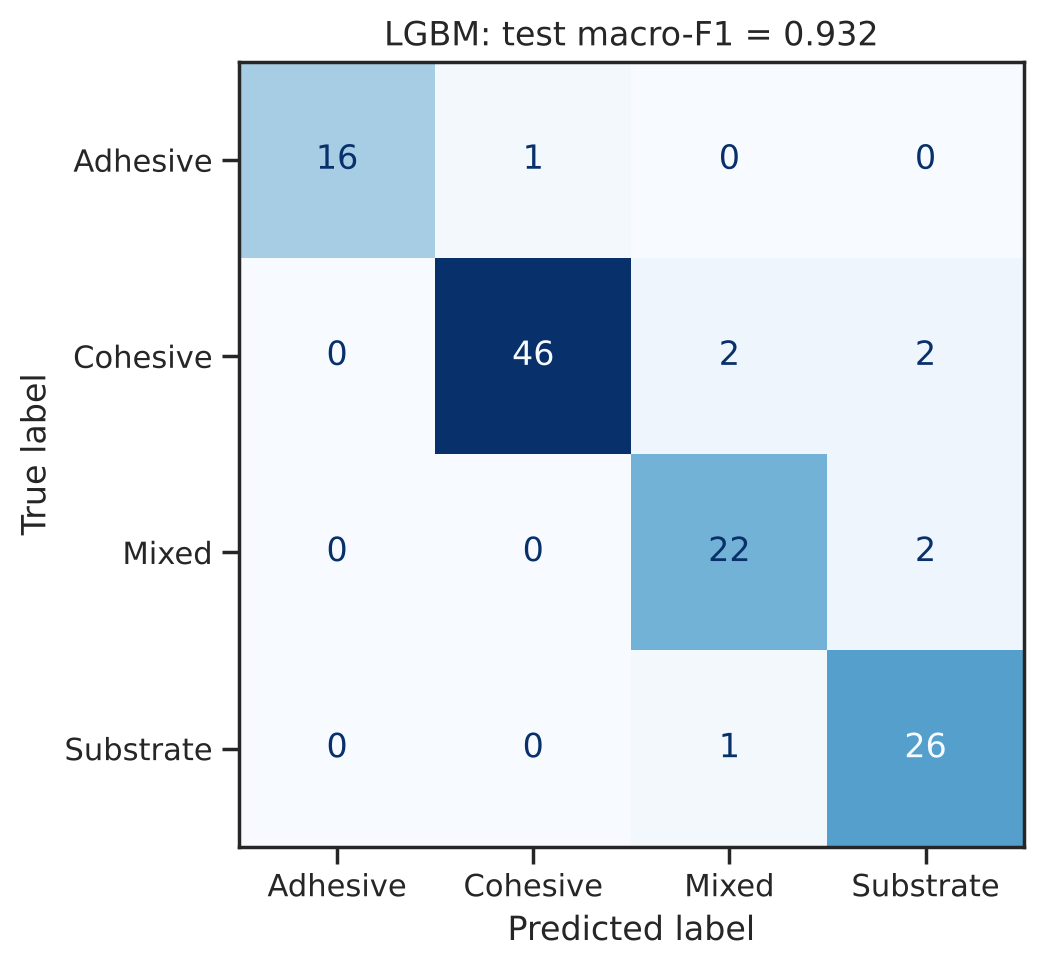

F1 per class: [0.97  0.948 0.898 0.912]


In [26]:
best_name = results_df.loc[results_df['Test_f1'].idxmax(), 'Model']
p = predictions[best_name]
labels = [0, 1, 2, 3]
cm = confusion_matrix(p['y_test'], p['pred_test'], labels=labels)
fig, ax = plt.subplots(figsize=(5.5, 5))
ConfusionMatrixDisplay(cm, display_labels=['Adhesive', 'Cohesive', 'Mixed', 'Substrate']).plot(ax=ax, cmap='Blues', colorbar=False)
ax.set_title(f'{best_name}: test macro-F1 = {results_df.set_index("Model").loc[best_name, "Test_f1"]:.3f}')
plt.tight_layout()
plt.show()
print('F1 per class:', np.round(f1_score(p['y_test'], p['pred_test'], average=None, labels=labels), 3))

## Permutation Importance

In [27]:
importance = {}
for name, fitted_model in fitted.items():
    r = permutation_importance(fitted_model, X_test, y_test, scoring=SCORING, n_repeats=3, random_state=0, n_jobs=2)
    importance[name] = r.importances_mean
importance = pd.DataFrame(importance, index=X.columns)
importance.to_csv(f'{RESULTS}/{TASK}__permutation_importance.csv')
importance.mean(axis=1).sort_values(ascending=False).head(12)

Surf_Laser                                 0.072630
Adhesive_Thickness_mm                      0.068097
Surf_Solvent_detergent_clean               0.052917
Fiber_Orientation_Class                    0.050069
Surf_Plasma_corona                         0.028656
Surf_Abrasion_sanding_grinding_brushing    0.028558
Fillet                                     0.020507
Surf_UV_ozone                              0.020334
Cure_Temp_C                                0.018756
Adhesive_Strength_MPa                      0.018270
Humidity_pctRH                             0.017760
Overlap_Length_mm                          0.017460
dtype: float64

## SHAP Analysis

In [28]:
# best tree-based model of the task
tree_models = ['RF', 'ET', 'XGB', 'LGBM', 'CatBoost', 'DT'] + ([] if True else ['GB'])
test_scores = results_df.set_index('Model')['Test_f1']
best_tree = test_scores[test_scores.index.isin(tree_models)].idxmax()
print('SHAP model:', best_tree)

pipe_tree = fitted[best_tree]
X_scaled = pd.DataFrame(pipe_tree[:-1].transform(X), columns=X.columns)
explainer = shap.TreeExplainer(pipe_tree[-1])
shap_values = explainer.shap_values(X_scaled, check_additivity=False)
if isinstance(shap_values, list):
    shap_values = np.stack(shap_values, axis=-1)
shap_values = np.asarray(shap_values)

# mean absolute SHAP value (averaged over classes for the classifiers)
abs_shap = np.abs(shap_values).mean(axis=tuple(i for i in range(shap_values.ndim) if i != 1))
importance_df = pd.DataFrame({'Feature': X.columns, 'Mean_Abs_SHAP': abs_shap}).sort_values('Mean_Abs_SHAP', ascending=False)
importance_df.to_csv(f'{RESULTS}/{TASK}__shap_importance.csv', index=False)
importance_df.head(12)

SHAP model: LGBM


,Feature,Mean_Abs_SHAP
15,Adhesive_Thickness_mm,1.139496
34,Surf_Solvent_detergent_clean,0.699499
3,Adherend1_Modulus_GPa,0.622564
13,Overlap_Length_mm,0.585677
35,Surf_Abrasion_sanding_grinding_brushing,0.478164
11,Adhesive_Strength_MPa,0.408775
0,No_Plies,0.396967
40,Surf_Laser,0.384534
12,Adhesive_Elongation_pct,0.324185
9,Mix_Ratio_A_per_B,0.318426


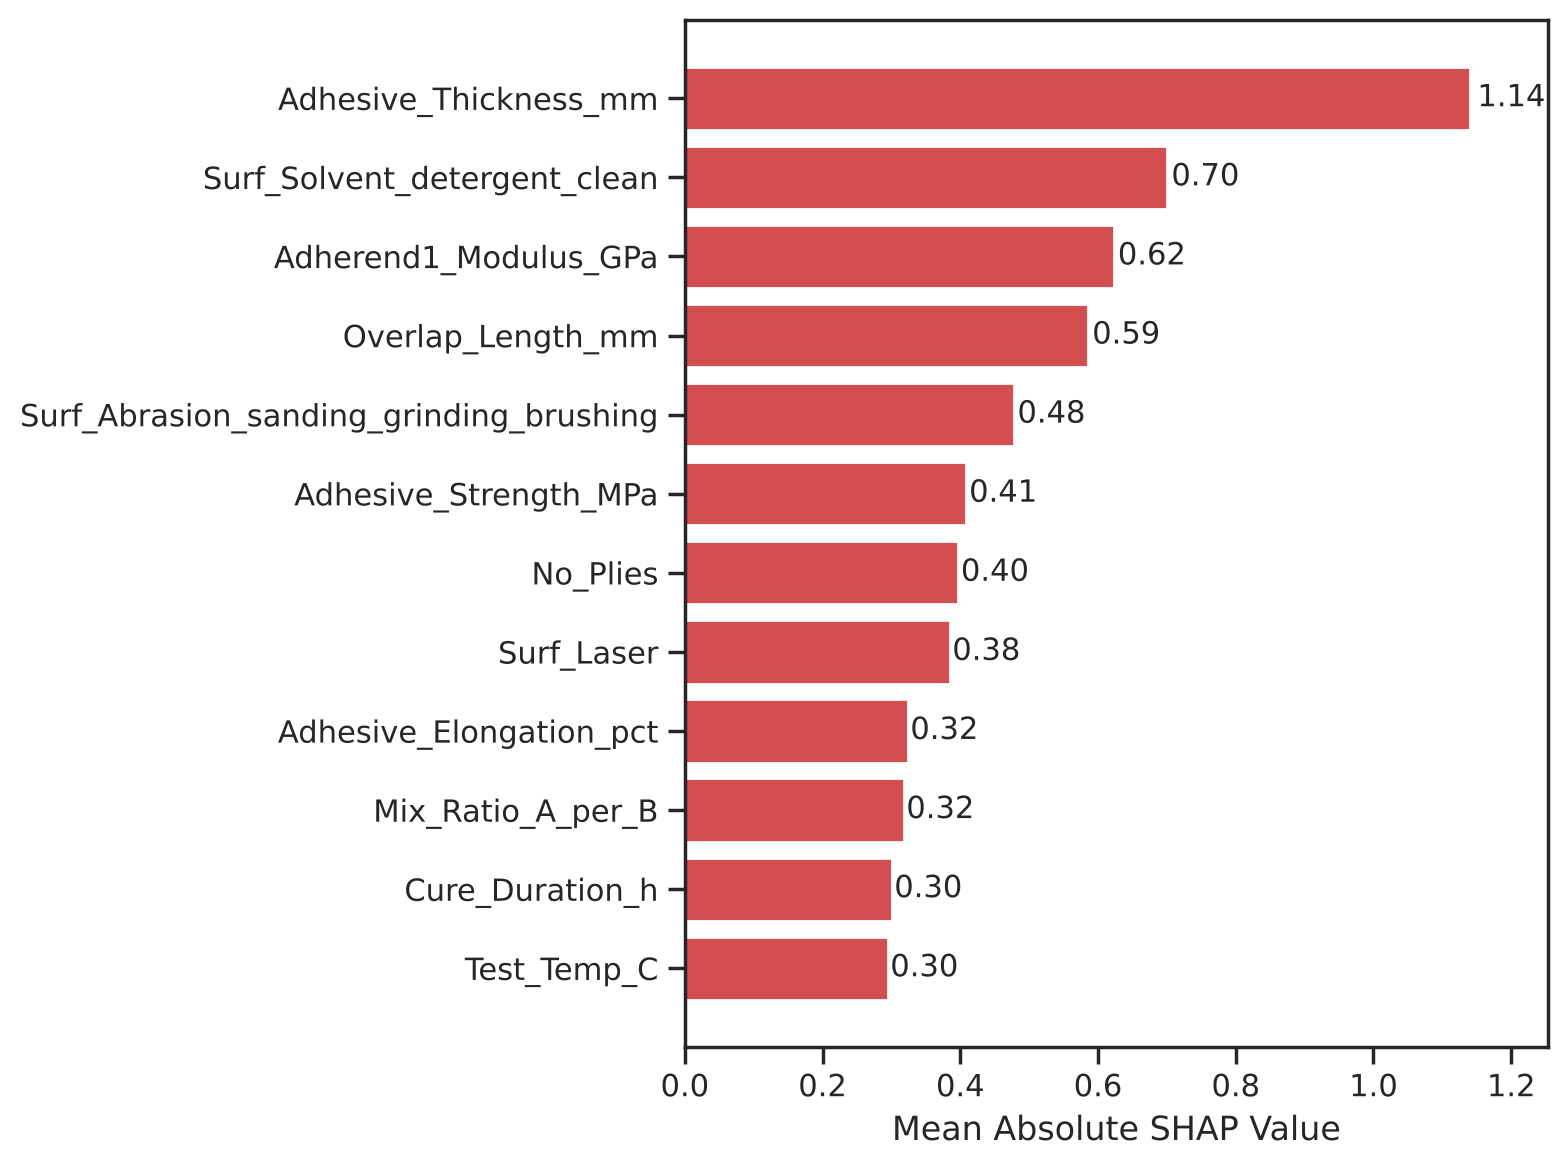

In [29]:
# Horizontal bar plot for feature importance with value labels
plt.figure(figsize=(8, 6))
top_features = importance_df.head(12).iloc[::-1]
bars = plt.barh(top_features['Feature'], top_features['Mean_Abs_SHAP'], color='#d34f4f')
for bar in bars:
    width = bar.get_width()
    plt.text(width * 1.01, bar.get_y() + bar.get_height() / 2, f'{width:.2f}', ha='left', va='center', fontsize=11)
plt.xlabel('Mean Absolute SHAP Value')
plt.margins(x=0.1)
plt.tight_layout()
plt.show()

## Save

In [30]:
with open(f'{RESULTS}/{TASK}__predictions.pkl', 'wb') as fh:
    pickle.dump(predictions, fh)
np.save(f'{RESULTS}/{TASK}__shap_values.npy', shap_values)